#### Load Packages

In [ ]:
suppressMessages(library(tidyverse))
suppressMessages(library(reshape2))

source("./Manuscript_files/theme_ggplot_cfrna.R")

In [2]:
samples <- read.delim("./Manuscript_files/sample_metadata.tsv")
gene.list <- read.delim("./Manuscript_files/gencode.biotype.name.key.tsv")
celltype.data <- read.delim("./Manuscript_files/decon_output_scrnaseq.tsv")

#### Plotting Code: Deconvoltion by Phenotype

In [3]:
results <- merge(samples, celltype.data, by.x="sample_id")
    
res_melt <- results %>% 
    reshape2::melt(.,id.vars = colnames(samples)) %>%
    rename(celltype = variable, fraction = value) %>%
    select(  all_of(c("sample_id", "celltype", "fraction", "phenotype", "tube_id", "sex", "test_site", "tube_id")))

head(res_melt, 4)

,sample_id,celltype,fraction,phenotype,tube_id,sex,test_site
,<chr>,<fct>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,cfs_cfrna_1,Naïve.CD4.T.cells,5.154507e-06,HC,ENID-261,F,LA
2,cfs_cfrna_11,Naïve.CD4.T.cells,7.634900e-06,MECFS,ENID-199,M,ITH
3,cfs_cfrna_12,Naïve.CD4.T.cells,8.446481e-06,MECFS,ENID-223,F,LA
4,cfs_cfrna_13,Naïve.CD4.T.cells,2.593262e-06,MECFS,ENID-424,F,ITH


In [4]:
##------------------------------------
# create res
sum <- res_melt %>% group_by(celltype) %>% summarize(mean=mean(fraction))
sum <- sum[order(sum$mean,decreasing=TRUE),]

celltypes_labels = sum$celltype

sumgroups <- res_melt %>%
  group_by(celltype, phenotype) %>%
  summarize(mean = mean(fraction))
sumgroups <- sumgroups[order(sumgroups$mean,decreasing=TRUE),]

head(sumgroups,10)

`summarise()` has grouped output by 'celltype'. You can override using the
`.groups` argument.


celltype,phenotype,mean
<fct>,<chr>,<dbl>
Platelets,HC,0.73158644
Platelets,MECFS,0.65385344
T.cells.1,MECFS,0.22760263
T.cells.1,HC,0.17577574
Monocytes.1,MECFS,0.03322541
Monocytes.1,HC,0.02990234
Monocytes.3,MECFS,0.02804799
Hematopoietic.stem.cells,HC,0.02454688
Hematopoietic.stem.cells,MECFS,0.02390130


In [5]:
# STATISTICAL TESTS
GROUPS = c("MECFS","HC")

compare_groups <- function(res_df,GROUP1, GROUP2){
    outputL = list()

    for (ct in unique(res_df$celltype)){

        G1val = res_df %>% filter(phenotype %in% GROUPS[1]) %>% filter(celltype == ct) %>% pull(fraction)
        G2val = res_df %>% filter(phenotype %in% GROUPS[2]) %>% filter(celltype == ct) %>% pull(fraction)

        wres = wilcox.test(G1val, G2val, alternative = "two.sided")
        wres_v <- c(GROUP1, GROUP2, ct, wres$p.value)
        
        outputL[[ct]] = wres_v

    }

    wildf <- data.frame(do.call("rbind",outputL))
    colnames(wildf) <- c("G1","G2","celltype","pval")

    return(wildf)
}
ct_comp = compare_groups(res_melt,GROUPS[1], GROUPS[2]) %>% remove_rownames()
ct_comp$padj <- p.adjust(ct_comp$pval, method = "BH")

ct_comp$padj <- as.numeric(ct_comp$padj)
ct_comp$pval <- as.numeric(ct_comp$pval)

ct_comp %>% arrange(pval) %>%
    mutate(padj = round(padj, 4), pval = round(pval, 4)) %>% 
    head(5)

,G1,G2,celltype,pval,padj
,<chr>,<chr>,<chr>,<dbl>,<dbl>
1,MECFS,HC,Plasmacytoid.dendritic.cells,0.0001,0.0015
2,MECFS,HC,Monocytes.3,0.0002,0.0033
3,MECFS,HC,Naïve.CD8.T.cells,0.0031,0.0229
4,MECFS,HC,T.cells.1,0.0035,0.0229
5,MECFS,HC,MAIT.cells,0.0041,0.0229


In [6]:
## SELECT TOP CELLS AND MAKE OTHER GROUP 
top10_celltypes <- sum %>% 
    top_n(10, mean) %>% 
    pull(celltype)

sumgroups_top10 <- sumgroups %>%
    filter(celltype %in% top10_celltypes)

sumgroups_other <- sumgroups %>% 
    filter(!(celltype %in% top10_celltypes)) %>%
    group_by(celltype, phenotype) %>%
    summarize(mean = sum(mean)) %>%
    mutate(celltype = "Other")

# Combine top rows with the "Other" rows
sumgroups_final <- bind_rows(sumgroups_top10, sumgroups_other)

val_vector = c('#B4436C', '#D1Ac00', '#FAF4D3', '#4d9078', '#BDC667', '#AEBBE6', '#92158B', '#6F392B', '#F76716', '#C47BF6', '#D91586', '#51FEA0', '#E008D2', '#175738', '#07BFE2', '#CBF01A', '#ECA6BF', '#D6AFE5', '#000EF6', '#FFE036', '#183956', '#4EA10F', '#630603', '#3CA6F2', '#55175D', '#A3D6EA', '#9390E8', '#212354', '#A012FF', '#303D95', '#C7F0A0', '#220793', '#2C8DAF', '#FB285F', '#91C846', '#4CFA1A', '#4F3F21', '#FC7FE3', '#FEC774', '#E50206', '#DED1A6', '#FB927F', '#09585E', '#4A5A21', '#17FFE1', '#6D0EB2', '#8F4A00', '#B9B00D', '#1EC7B8', '#8E104E', '#FE74A4', '#6F7B1E', '#A9DAC9', '#0C56E5', '#239A56', '#F09601', '#CEAA91', '#02760D', '#521F2F', '#B36A4A', '#06C968', '#9D7924')
val_vector = val_vector[1:length(celltypes_labels)]
names(val_vector) = celltypes_labels

`summarise()` has grouped output by 'celltype'. You can override using the
`.groups` argument.


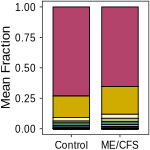

In [7]:
# TOP AVERAGE CELL TYPE FRACTIONS
width = 1.25
height = 1.25
options(repr.plot.width = width, repr.plot.height = height)

plot_name <- "D1_avg_celltypes_SCmax"

plot_me <- sumgroups_final %>%
  mutate(celltype = factor(celltype, levels = unique(sumgroups_final$celltype))) %>%
  ggplot(aes(x = phenotype, y = mean, fill = celltype)) +
  geom_bar(position = "stack", stat = "identity", colour = "black", width = 0.75, lwd = 0.25) +
  theme_cfrna_paper() +
  scale_fill_manual(values = val_vector) +
  labs(x = NULL, y = "Mean Fraction") +
  scale_x_discrete(labels = c("MECFS" = "ME/CFS", "HC" = "Control")) 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_3/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

In [8]:
width = 1
height = 1.25
options(repr.plot.width = width, repr.plot.height = height)

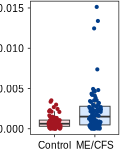

In [9]:
# PLASMACYTOID DENDRITIC CELL FRACTION
plot_name <- "D1_pdcs_SCmax2"
plot_this_cell <- "Plasmacytoid.dendritic.cells"

# Filter the data for the cell type
filtered_data <- res_melt %>%
  filter(celltype == plot_this_cell)
  cell_type <- unique(filtered_data$celltype)

plot_me <- filtered_data %>%
  ggplot(aes(x = phenotype, y = fraction, fill = phenotype)) +
  geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
  geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.3), alpha = 1, size = 0.5) +
  scale_color_manual(values = COLORS) +
  scale_fill_manual(values = COLORS_FILL) +
  scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
  theme_cfrna_paper() +
  labs(y = NULL, x = NULL) 

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_3/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

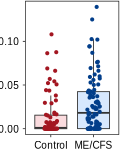

In [10]:
# MONOCYTE FRACTION
plot_name <- "D1_mono3_SCmax2"
plot_this_cell <- "Monocytes.3"

# Filter the data for the cell type
filtered_data <- res_melt %>%
  filter(celltype == plot_this_cell)
  cell_type <- unique(filtered_data$celltype)

plot_me <- filtered_data %>%
  ggplot(aes(x = phenotype, y = fraction, fill = phenotype)) +
  geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
  geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.3), alpha = 1, size = 0.5) +
  scale_color_manual(values = COLORS) +
  scale_fill_manual(values = COLORS_FILL) +
  scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
  scale_y_continuous(breaks = seq(0, 1, by = 0.05)) +
  theme_cfrna_paper() +
  labs(y = NULL, x = NULL)
  
plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_3/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

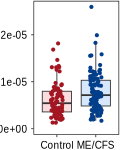

In [11]:
# NAIVE CD8 T CELL FRACTION
plot_name <- "D1_naiveCD8_SCmax2"
plot_this_cell <- "Naïve.CD8.T.cells"

# Filter the data for the cell type
filtered_data <- res_melt %>%
  filter(celltype == plot_this_cell)
  cell_type <- unique(filtered_data$celltype)

plot_me <- filtered_data %>%
  ggplot(aes(x = phenotype, y = fraction, fill = phenotype)) +
  geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
  geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.3), alpha = 1, size = 0.5) +
  scale_color_manual(values = COLORS) +
  scale_fill_manual(values = COLORS_FILL) +
  scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
  scale_y_continuous(limits = c(0, NA)) +
  theme_cfrna_paper() +
  labs(y = NULL, x = NULL)

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_3/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

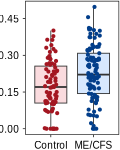

In [12]:
# T CELL FRACTION
plot_name <- "D1_Tcells1_SCmax2"
plot_this_cell <- "T.cells.1"

# Filter the data for the cell type
filtered_data <- res_melt %>%
  filter(celltype == plot_this_cell)
  cell_type <- unique(filtered_data$celltype)

plot_me <- filtered_data %>%
  ggplot(aes(x = phenotype, y = fraction, fill = phenotype)) +
  geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
  geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.3), alpha = 1, size = 0.5) +
  scale_color_manual(values = COLORS) +
  scale_fill_manual(values = COLORS_FILL) +
  scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
  scale_y_continuous(breaks = seq(0, 1, by = 0.15)) +
  theme_cfrna_paper() +
  labs(y = NULL, x = NULL)
  
plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_3/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

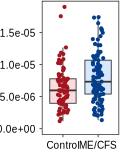

In [13]:
# MAIT CELL FRACTION
plot_name <- "D1_mait_SCmax2"
plot_this_cell <- "MAIT.cells"

# Filter the data for the cell type
filtered_data <- res_melt %>%
  filter(celltype == plot_this_cell)
  cell_type <- unique(filtered_data$celltype)

plot_me <- filtered_data %>%
  ggplot(aes(x = phenotype, y = fraction, fill = phenotype)) +
  geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
  geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.3), alpha = 1, size = 0.5) +
  scale_color_manual(values = COLORS) +
  scale_fill_manual(values = COLORS_FILL) +
  scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
  ylim(0, NA) +
  theme_cfrna_paper() +
  labs(y = NULL, x = NULL)
  
plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_3/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

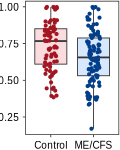

In [14]:
# PLATELET FRACTION
plot_name <- "D1_platelets_SCmax2"
plot_this_cell <- "Platelets"

# Filter the data for the cell type
filtered_data <- res_melt %>%
  filter(celltype == plot_this_cell)
  cell_type <- unique(filtered_data$celltype)

plot_me <- filtered_data %>%
  ggplot(aes(x = phenotype, y = fraction, fill = phenotype)) +
  geom_boxplot(width = 0.75, outlier.shape = NA, lwd = 0.25) + 
  geom_jitter(aes(color = phenotype), position = position_jitterdodge(jitter.width = 0.3), alpha = 1, size = 0.5) +
  scale_color_manual(values = COLORS) +
  scale_fill_manual(values = COLORS_FILL) +
  scale_x_discrete(labels = c("HC" = "Control", "MECFS" = "ME/CFS")) +
  theme_cfrna_paper() +
  labs(y = NULL, x = NULL)
  
plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_3/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)

#### Plotting Code: Sex Seperated Differences

In [15]:
# Aggregate data to calculate average fractions
fraction_summary <- res_melt %>%
  group_by(celltype, sex, phenotype) %>%
  summarise(
    avg_fraction = mean(fraction, na.rm = TRUE),
    .groups = "drop"
  )

# Create a "group" column for plotting
fraction_summary <- fraction_summary %>%
  mutate(group = paste(sex, phenotype, sep = "-")) %>%
  mutate(celltype = factor(celltype, levels = unique(sum$celltype)))

In [16]:
# STATISTICAL TESTS FOR EACH SEX
compare_groups <- function(res_df, GROUP1, GROUP2, sex_filter){
    outputL = list()

    for (ct in unique(res_df$celltype)){
        G1val = res_df %>% filter(phenotype %in% GROUP1, sex == sex_filter) %>% filter(celltype == ct) %>% pull(fraction)
        G2val = res_df %>% filter(phenotype %in% GROUP2, sex == sex_filter) %>% filter(celltype == ct) %>% pull(fraction)

        wres = wilcox.test(G1val, G2val, alternative = "two.sided")
        wres_v <- c(GROUP1, GROUP2, ct, wres$p.value)
        
        outputL[[ct]] = wres_v
    }

    wildf <- data.frame(do.call("rbind", outputL))
    colnames(wildf) <- c("G1", "G2", "celltype", "pval")

    return(wildf)
}

# STATISTICAL TESTS FOR FEMALES
ct_comp_females = compare_groups(res_melt, GROUPS[1], GROUPS[2], "F") %>% remove_rownames()
ct_comp_females$padj <- p.adjust(ct_comp_females$pval, method = "BH")
ct_comp_females$padj <- as.numeric(ct_comp_females$padj)
ct_comp_females$pval <- as.numeric(ct_comp_females$pval)

ct_comp_females %>% arrange(pval) %>%
    mutate(padj = round(padj, 4), pval = round(pval, 4)) %>% 
    head(10)

# STATISTICAL TESTS FOR MALES
ct_comp_males = compare_groups(res_melt, GROUPS[1], GROUPS[2], "M") %>% remove_rownames()
ct_comp_males$padj <- p.adjust(ct_comp_males$pval, method = "BH")
ct_comp_males$padj <- as.numeric(ct_comp_males$padj)
ct_comp_males$pval <- as.numeric(ct_comp_males$pval)

ct_comp_males %>% arrange(pval) %>%
    mutate(padj = round(padj, 4), pval = round(pval, 4)) %>% 
    head(10)

,G1,G2,celltype,pval,padj
,<chr>,<chr>,<chr>,<dbl>,<dbl>
1,MECFS,HC,Monocytes.3,0.0015,0.0225
2,MECFS,HC,Plasmacytoid.dendritic.cells,0.0016,0.0225
3,MECFS,HC,Effector.Memory.CD8.T.cells.2,0.0041,0.0290
4,MECFS,HC,MAIT.cells,0.0041,0.0290
5,MECFS,HC,T.cells.1,0.0067,0.0373
6,MECFS,HC,Platelets,0.0096,0.0449
7,MECFS,HC,Naïve.CD8.T.cells,0.0141,0.0563
8,MECFS,HC,Intermediate.monocytes,0.0489,0.1467
9,MECFS,HC,Effector.Memory.CD4.T.cells,0.0518,0.1467


,G1,G2,celltype,pval,padj
,<chr>,<chr>,<chr>,<dbl>,<dbl>
1,MECFS,HC,Plasmacytoid.dendritic.cells,0.0250,0.7011
2,MECFS,HC,Monocytes.3,0.0575,0.8048
3,MECFS,HC,Non.classical.monocytes,0.2181,0.8943
4,MECFS,HC,Plasmablasts,0.2585,0.8943
5,MECFS,HC,Gamma.delta.T.cells.2,0.3036,0.8943
6,MECFS,HC,T.cells.1,0.3280,0.8943
7,MECFS,HC,Naïve.CD8.T.cells,0.3406,0.8943
8,MECFS,HC,T.cells.2,0.3406,0.8943
9,MECFS,HC,Proliferating.cells,0.3804,0.8943


In [17]:
ct_comp_sort <- ct_comp %>% arrange(pval)

head(ct_comp_sort)
nrow(ct_comp)

,G1,G2,celltype,pval,padj
,<chr>,<chr>,<chr>,<dbl>,<dbl>
1,MECFS,HC,Plasmacytoid.dendritic.cells,5.433894e-05,0.001521490
2,MECFS,HC,Monocytes.3,2.372958e-04,0.003322141
3,MECFS,HC,Naïve.CD8.T.cells,3.099383e-03,0.022873375
4,MECFS,HC,T.cells.1,3.506858e-03,0.022873375
5,MECFS,HC,MAIT.cells,4.084531e-03,0.022873375
6,MECFS,HC,Platelets,5.670190e-03,0.026460889


[1] 28

In [ ]:
# The Z-score reflects how far the fraction deviates from the mean 
# The mean (μ) and standard deviation (σ) of the average fraction are computed across all phenotypes

# Create a "group" column for plotting
fraction_summary <- fraction_summary %>%
  mutate(group = paste(sex, phenotype, sep = "-")) %>%
  mutate(celltype = factor(celltype, levels = unique(ct_comp_sort$celltype)))

fraction_summary_zscore <- fraction_summary %>%
  group_by(celltype) %>%
  mutate(
    zscore_fraction = (avg_fraction - mean(avg_fraction)) / sd(avg_fraction)  # Z-score normalization
  ) %>%
  ungroup()

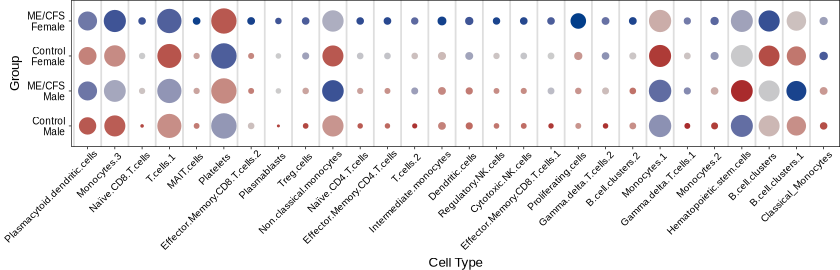

In [19]:
# CELL TYPE FRACTION AND Z-SCORE BY SEX AND PHENOTYPE
width = 7
height = 2.25
options(repr.plot.width = width, repr.plot.height = height)

plot_name <- "D1_dotplot_SCmax_MF"

# Calculate positions for vertical lines (midpoints between cell types)
unique_celltypes <- unique(fraction_summary_zscore$celltype)
vline_positions <- seq_along(unique_celltypes) - 0.5

plot_me <- ggplot(fraction_summary_zscore, aes(x = celltype, y = group, size = avg_fraction, color = zscore_fraction)) +
  geom_vline(xintercept = vline_positions, color = "gray", alpha = 0.5) + 
  geom_point(alpha = 1) + 
  scale_size_continuous(
    range = c(.2, 6.5), # bubble sizes for better visibility
    trans = "log10", # log10 transformation for clearer interpretation
    breaks = c(1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 0.5), # meaningful legend breaks
    name = "Avg Fraction\n(Log10 Scale)") +
  scale_color_gradient2(
    high = "#023E8A", mid = "gray80", low = "#a31621", midpoint = 0, 
    name = "Z-Score") + 
  theme_cfrna_paper() +
  theme(axis.text.x = element_text(angle = 45, hjust = .95) , 
      legend.position = "none") +
  scale_y_discrete(limits = c("M-HC", "M-MECFS", "F-HC", "F-MECFS"), 
                  labels = c("F-HC" = "Control\nFemale", "F-MECFS" = "ME/CFS\nFemale", 
                             "M-HC" = "Control\nMale", "M-MECFS" = "ME/CFS\nMale")) +
  labs(
    title = NULL,
    x = "Cell Type", 
    y = "Group",
    size = "Avg Fraction\n(Log10 Scale)",
    color = "Z-Score") +
    theme(plot.margin = margin(l = 6))

plot_me

# Save the plot as a PDF
ggsave(paste0("./Figure_outputs/figure_3/", plot_name, ".pdf"), plot = plot_me, width = width, height = height)